# How much ground does each student get?

NSW government schools in inner Sydney and Parramatta publish a code, a name, a location and 22 years of headcounts.
They do not publish the school grounds. Without a shape there is no area, and without an area there is no "per square
metre". The shapes in `data/geometry/` were made in [Plotlay](https://www.getplotlay.com): NSW Cadastre lots picked and
merged for each school, and the few schools without a lot of their own drawn over the NSW aerial imagery. Each shape
carries its school code, so it joins to the department's tables.

This notebook reads only the files in `../data`, recomputes every number it shows, and runs top to bottom in under a
minute.

In [1]:
import json
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

DATA = '../data'
pd.set_option('display.width', 140)
INK, RED, MUTED, FILM = '#1d4f91', '#cf3b26', '#5b6573', '#f2efe6'
BINS = [0, 10, 15, 25, 50, np.inf]
BIN_LABELS = ['under 10 m²', '10 to 15', '15 to 25', '25 to 50', '50 m² or more']
BIN_COLOURS = ['#6b1a10', '#b8321f', '#e0714a', '#f0aa82', '#f8dcc6']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})

## Sources and licence

School data: NSW Department of Education (Centre for Education Statistics and Evaluation), data.nsw.gov.au, under
Creative Commons Attribution (CC BY). Cadastre and aerial imagery: © State of New South Wales (Spatial Services), CC BY
3.0 AU. The outlines were made in Plotlay from NSW Cadastre lots and drawn over NSW Imagery; there is nothing from
OpenStreetMap in this repository. The full credits are in `NOTICE`.

## Load the tables

One row per school (`schools.csv`) and two long tables with a row per school and year. Headcounts of 5 or fewer are
published as `SP` (suppressed): they stay blank and are never filled in or worked out from totals. None of the 81
schools here has a suppressed headcount.

In [2]:
schools = pd.read_csv(f'{DATA}/schools/schools.csv')
enrol = pd.read_csv(f'{DATA}/schools/enrolments_long.csv')
att = pd.read_csv(f'{DATA}/schools/attendance_long.csv')
assert schools.school_key.is_unique
assert not enrol.duplicated(['school_key', 'year']).any()
assert (enrol.students > 0).all(), 'blanks stay blank: no zeros stand in for suppressed values'
print(len(schools), 'schools;', len(enrol), 'school-years of headcount;', len(att), 'of attendance')
schools[['school_key', 'school_name', 'level', 'opened', 'shape_source', 'outline_check']].head()

81 schools; 1686 school-years of headcount; 946 of attendance


,school_key,school_name,level,opened,shape_source,outline_check
0,8913,Inner Sydney High School,Secondary School,2020-01-28,NSW Cadastre lots,ok
1,8135,Parramatta High School,Secondary School,1913-01-01,NSW Cadastre lots,ok
2,8892,Arthur Phillip High School,Secondary School,1958-01-01,NSW Cadastre lots,ok
3,7442,Woollahra Public School,Primary School,1878-03-01,NSW Cadastre lots,ok
4,3305,Ultimo Public School,Primary School,1858-01-10,NSW Cadastre lots,ok


## Load the shapes

The GeoJSON is the Plotlay export: WGS 84 longitude and latitude, a `key` (the school code) on every shape, `area_m2`,
and `source` saying how the outline was made. The areas are checked here in a metre grid (GDA2020 MGA zone 56,
EPSG:7856), not in degrees.

In [3]:
shapes = gpd.read_file(f'{DATA}/geometry/schools.geojson')
shapes['school_key'] = shapes['key'].astype(int)
shapes['grounds_m2'] = shapes['area_m2']                 # the area Plotlay exported
shapes['area_7856'] = shapes.to_crs(7856).area          # the same outlines measured here
assert shapes.school_key.is_unique
diff = (shapes.area_7856 - shapes.grounds_m2).abs() / shapes.area_7856
print(f'{len(shapes)} shapes; largest difference between the Plotlay area and EPSG:7856: {diff.max():.2%}')
shapes.source.value_counts()

81 shapes; largest difference between the Plotlay area and EPSG:7856: 0.11%


source
NSW Cadastre (Spatial Services)    75
Drawn over NSW aerial imagery       6
Name: count, dtype: int64

## The join

The key is the whole trick: one shared column. Every school in the tables should have exactly one shape.

In [4]:
g = shapes[['school_key', 'grounds_m2', 'source', 'geometry']].merge(schools.drop(columns=['grounds_m2']), on='school_key', how='right', validate='one_to_one', indicator=True)
print(g['_merge'].value_counts().to_dict())
g = gpd.GeoDataFrame(g.drop(columns='_merge'), geometry='geometry', crs=4326)
long = enrol.merge(g[['school_key', 'school_name', 'level', 'grounds_m2', 'compare']], on='school_key', validate='many_to_one', suffixes=('_t', ''))
long['m2_per_student'] = long.grounds_m2 / long.students

{'both': 81, 'left_only': 0, 'right_only': 0}


## Ground per student, 2025

Grounds are the land a school sits on, buildings included. They are not floor space and not playground area, and
parks or sports grounds next door are not counted. Schools are compared only when they are mainstream (not schools for
specific purposes) and their outline passed the check on the aerial imagery (`compare` is true): see
`data/schools/outline_checklist.csv`.

In [5]:
y25 = long[long.year == 2025].copy()
cmp25 = y25[y25['compare']]
med = cmp25.groupby('level').m2_per_student.agg(['median', 'count']).round(1)
display(med.loc[['Primary School', 'Secondary School']])
ish = y25.set_index('school_name').loc['Inner Sydney High School']
fsh = y25.set_index('school_name').loc['Fort Street High School']
print(f"Inner Sydney High: {ish.students:,.0f} students on {ish.grounds_m2:,.0f} m², {ish.m2_per_student:.1f} m² each")
print(f"Fort Street High: {fsh.students:,.0f} students on {fsh.grounds_m2:,.0f} m², {fsh.m2_per_student:.1f} m² each ({fsh.m2_per_student / ish.m2_per_student:.1f} times as much)")

,median,count
level,,
Primary School,30.3,49
Secondary School,29.3,16


Inner Sydney High: 1,161 students on 5,687 m², 4.9 m² each
Fort Street High: 917 students on 39,839 m², 43.4 m² each (8.9 times as much)


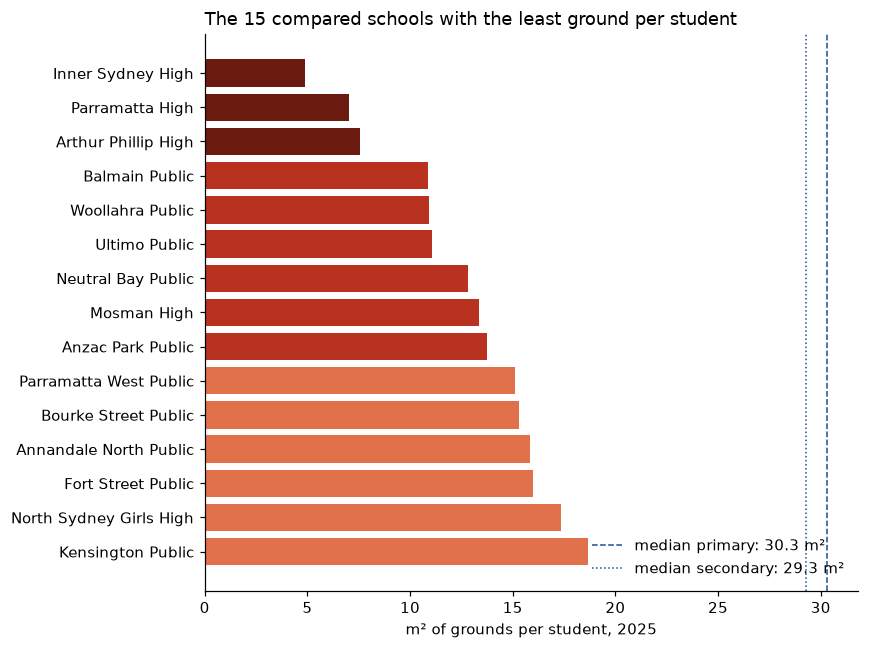

In [6]:
tight = cmp25.sort_values('m2_per_student').head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
colours = [BIN_COLOURS[np.digitize(v, BINS[1:-1])] for v in tight.m2_per_student]
ax.barh(tight.school_name.str.replace(' School', ''), tight.m2_per_student, color=colours)
for lvl, ls in [('Primary School', '--'), ('Secondary School', ':')]:
    ax.axvline(med.loc[lvl, 'median'], color=INK, ls=ls, lw=1, label=f"median {lvl.split()[0].lower()}: {med.loc[lvl, 'median']} m²")
ax.set_xlabel('m² of grounds per student, 2025'); ax.legend(frameon=False, loc='lower right')
ax.set_title('The 15 compared schools with the least ground per student', loc='left')
plt.tight_layout(); plt.show()

## Vertical schools

Inner Sydney High School opened in January 2020 with a 14-storey tower for up to 1,200 students (School Infrastructure
NSW). Arthur Phillip High School in Parramatta, rebuilt for 2,000 students, was the first high-rise public high school in
NSW. A vertical school stacks its classrooms, so its floor space per student is far more than its ground per student.
The point of the numbers below is that vertical schools fit many students on a small piece of land, not that any school
is short of room inside.

In [7]:
fill = long[long.school_name == 'Inner Sydney High School'][['year', 'students', 'm2_per_student']].round(1)
fill[fill.year >= 2020].set_index('year').T

year,2020,2021,2022,2023,2024,2025
students,147.0,358.0,591.0,797.0,999.0,1161.0
m2_per_student,38.7,15.9,9.6,7.1,5.7,4.9


## Make it human scale

A standard car space (AS/NZS 2890.1, user class 1A) is 2.4 × 5.4 m, 12.96 m².

4.9 m² is 38% of a car space; a square of it is 2.21 m a side


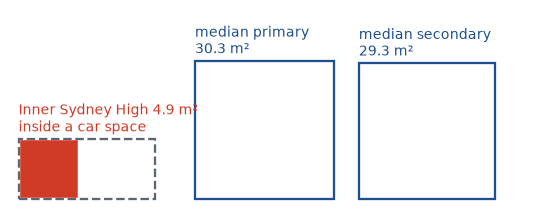

In [8]:
car = 2.4 * 5.4
v = ish.m2_per_student
print(f"{v:.1f} m² is {v / car:.0%} of a car space; a square of it is {np.sqrt(v):.2f} m a side")
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.add_patch(Rectangle((0, 0), 5.4, 2.4, fill=False, ls='--', ec=MUTED, lw=1.5))
s = np.sqrt(v); ax.add_patch(Rectangle((0.1, 0.1), s, s, color=RED))
for i, (lvl, x0) in enumerate([('Primary School', 7), ('Secondary School', 7 + np.sqrt(med.loc['Primary School', 'median']) + 1)]):
    m = med.loc[lvl, 'median']; ax.add_patch(Rectangle((x0, 0), np.sqrt(m), np.sqrt(m), fill=False, ec=INK, lw=1.5))
    ax.text(x0, np.sqrt(m) + 0.3, f"median {lvl.split()[0].lower()}\n{m} m²", fontsize=9, color=INK)
ax.text(0, 2.7, f'Inner Sydney High {v:.1f} m²\ninside a car space', fontsize=9, color=RED)
ax.set_xlim(-0.3, 20); ax.set_ylim(-0.3, 7.5); ax.set_aspect('equal'); ax.axis('off')
plt.show()

## The map

Coloured by m² of grounds per student in 2025, in the same five bands as the story visuals. Grey: not compared (a
school for specific purposes, or an outline that could not be checked). No basemap: nothing is downloaded.

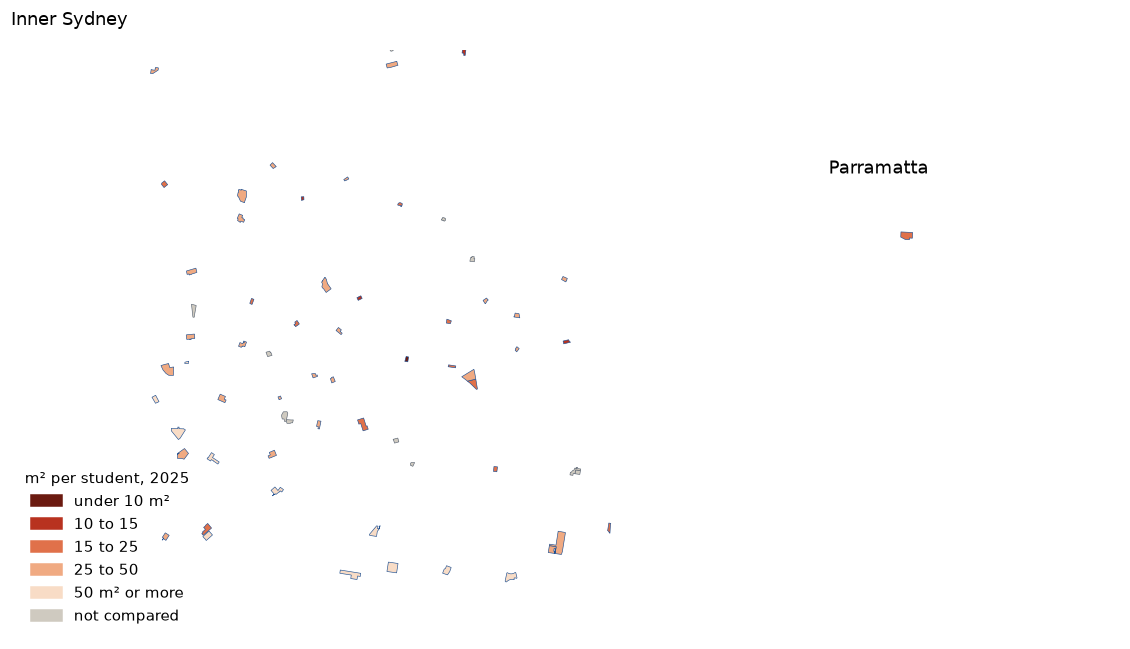

In [9]:
m = g.merge(y25[['school_key', 'm2_per_student']], on='school_key', how='left').to_crs(7856)
m['band'] = pd.cut(m.m2_per_student, BINS, labels=BIN_LABELS, right=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 6), gridspec_kw={'width_ratios': [3, 1]})
for ax, box in zip(axes, [(326000, 6243000, 341000, 6255000), (313000, 6252000, 317000, 6256000)]):
    for lab, col in zip(BIN_LABELS, BIN_COLOURS):
        part = m[(m.band == lab) & m['compare']]
        if len(part): part.plot(ax=ax, color=col, edgecolor=INK, lw=0.4)
    m[~m['compare']].plot(ax=ax, color='#cfcac0', edgecolor=MUTED, lw=0.4)
    ax.set_xlim(box[0], box[2]); ax.set_ylim(box[1], box[3]); ax.set_axis_off(); ax.set_aspect('equal')
axes[0].set_title('Inner Sydney', loc='left'); axes[1].set_title('Parramatta', loc='left')
handles = [Rectangle((0, 0), 1, 1, color=c) for c in BIN_COLOURS] + [Rectangle((0, 0), 1, 1, color='#cfcac0')]
axes[0].legend(handles, BIN_LABELS + ['not compared'], loc='lower left', frameon=False, title='m² per student, 2025')
plt.tight_layout(); plt.show()

## Watching it fill

Headcount for the schools that opened or were rebuilt since 2015.

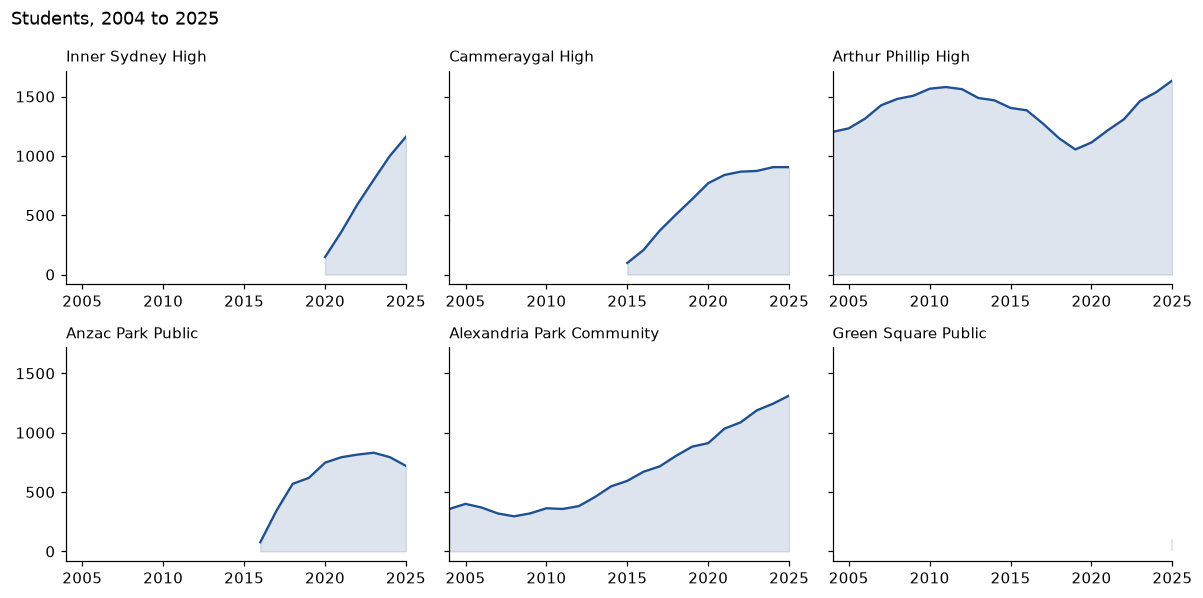

In [10]:
picks = ['Inner Sydney High School', 'Cammeraygal High School', 'Arthur Phillip High School', 'Anzac Park Public School', 'Alexandria Park Community School', 'Green Square Public School']
fig, axes = plt.subplots(2, 3, figsize=(11, 5.5), sharey=True)
for ax, n in zip(axes.flat, picks):
    s = long[long.school_name == n]
    ax.fill_between(s.year, s.students, color=INK, alpha=.15); ax.plot(s.year, s.students, color=INK)
    ax.set_title(n.replace(' School', ''), loc='left', fontsize=10); ax.set_xlim(2004, 2025)
fig.suptitle('Students, 2004 to 2025', x=0.01, ha='left'); plt.tight_layout(); plt.show()

## The squeeze moved up

Primary and high school totals in the study area. Randwick High is a 2025 merger of Randwick Boys and Randwick Girls
High; their earlier headcounts are in `randwick_before_merger` so the high school line is like for like.

Primary School: 24,389 (2019) to 20,641 (2025), -15.4%
Secondary School: 17,035 (2019) to 19,242 (2025), +13.0%


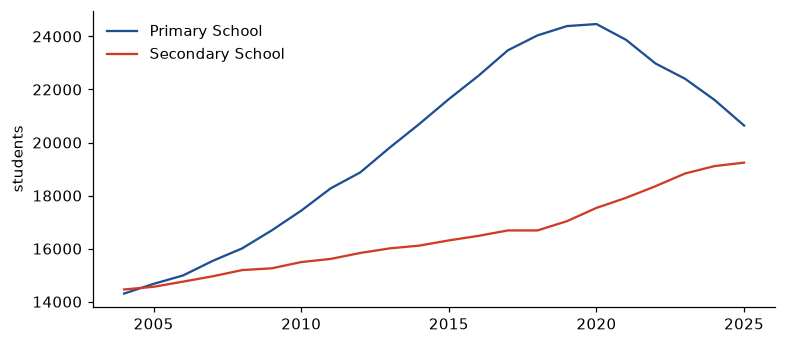

In [11]:
lvl = long[long.level.isin(['Primary School', 'Secondary School'])].groupby(['year', 'level']).students.sum().unstack()
pre = pd.read_csv(f'{DATA}/schools/randwick_before_merger.csv').set_index('year').students
lvl['Secondary School'] = lvl['Secondary School'].add(pre, fill_value=0)
for k in lvl: print(f"{k}: {lvl.loc[2019, k]:,.0f} (2019) to {lvl.loc[2025, k]:,.0f} (2025), {lvl.loc[2025, k] / lvl.loc[2019, k] - 1:+.1%}")
ax = lvl.plot(figsize=(8, 3.5), color=[INK, RED]); ax.set_xlabel(''); ax.set_ylabel('students'); ax.legend(frameon=False)
plt.show()

## Attendance

Semester 1 attendance. There is no 2020 data, and the department says 2021 is not comparable with other years.

In [12]:
a = att.pivot_table(index='school_key', columns='year', values='attendance_pct')
print('mean attendance:', a.mean().round(1).loc[[2019, 2022, 2024]].to_dict())
both = a[[2019, 2024]].dropna()
print(f'{(both[2024] < both[2019]).sum()} of {len(both)} schools were below their 2019 attendance in 2024')
r = cmp25.merge(a[2024].rename('att_2024'), left_on='school_key', right_index=True).dropna(subset=['att_2024'])
print(f"Spearman correlation of ground per student and 2024 attendance: {r[['m2_per_student', 'att_2024']].corr('spearman').iloc[0, 1]:.2f} ({len(r)} schools): no clear link")

mean attendance: {2019: 93.7, 2022: 88.0, 2024: 90.3}
68 of 72 schools were below their 2019 attendance in 2024
Spearman correlation of ground per student and 2024 attendance: -0.24 (66 schools): no clear link


## Caveats

- Grounds are land, buildings included: not floor space, not playground area. Parks next door are not counted.
- Areas are as picked or drawn and are approximate. Accuracy depends on the cadastre and the imagery.
- Headcount, not capacity: the open data has no capacity figures, so nothing here says a school is over capacity.
- Suppressed headcounts stay blank.
- Ground per student and attendance are shown side by side; no cause is claimed.

## Checks

If a shape changes, these catch it.

In [13]:
assert 4.6 <= ish.m2_per_student <= 5.2, ish.m2_per_student
assert 8 <= fsh.m2_per_student / ish.m2_per_student <= 10
assert g.geometry.notna().all() and len(g) == 81
out = y25[['school_key', 'school_name', 'level', 'students', 'grounds_m2', 'm2_per_student', 'compare']].round(1)
print('all checks passed;', len(out), 'schools in the 2025 table')

all checks passed; 81 schools in the 2025 table
